# Week 09 과제 — 뉴스 명사 빈도 분석 및 워드클라우드

## 분석 대상
뉴시스, 「기후변화 대응을 위한 도시 녹지 확충」 관련 기사 (`news.txt`)
- 출처: https://www.newsis.com/view/NISX20250205_0003054569

## 사용한 불용어 리스트
`위해`, `반영`, `대해`, `이번`, `통해`, `지난`, `뉴시스`, `이재은`, `이수연`

(1글자 명사는 별도로 제거)

## 버전 정보
| 항목 | 버전 |
|---|---|
| Python | 3.11.17 |
| OS | macOS 27.0.1 (arm64) |
| Java (OpenJDK, KoNLPy용) | 25 |
| konlpy | 0.6.0 |
| JPype1 | 1.7.1 |
| wordcloud | 1.9.6 |
| matplotlib | 3.11.2 |
| numpy | 2.4.6 |
| pillow | 13.0.0 |
| 한글 폰트 | AppleGothic |

In [13]:
from wordcloud import WordCloud
from konlpy.tag import Okt
from collections import Counter
import re
from pathlib import Path
import matplotlib.pyplot as plt

# 산출물 저장 폴더
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

# 한글 폰트 설정 (맥 기준)
plt.rcParams['font.family'] = 'AppleGothic'  # 맥 기본 한글 폰트
plt.rcParams['axes.unicode_minus'] = False
font_path = "/System/Library/Fonts/Supplemental/AppleGothic.ttf"  # 워드클라우드용 폰트 파일 경로

In [14]:
# 1~7 단어 전처리

# 1) 형태소 분석기 준비
# - Okt(Open Korean Text)는 한국어 형태소 분석기 중 하나로,
#   SNS/연설문 같은 자연스러운 문체에서 좋은 성능을 보인다.
okt = Okt()

# 2) 뉴스 불러오기
# - news.txt 불러오기
# - UTF-8 인코딩을 사용 (윈도우에서 인코딩 오류가 날 경우 'cp949'로 변경 가능)
with open("news.txt", encoding="utf-8") as f:
    text = f.read()

# 3) 정규화: 한글과 공백만 남기기
# - [^가-힣\s] : 한글(가~힣)과 공백(\s)을 제외한 모든 문자를 찾아 공백으로 대체
# - 여러 공백을 하나로 줄이고, 문장 앞뒤 공백을 제거한다.
text = re.sub(r"[^가-힣\s]", " ", text)
text = re.sub(r"\s+", " ", text).strip()

# 4) 형태소 분석 & 명사 추출
# - okt.nouns()는 문장에서 명사만 추출해 리스트 형태로 반환한다.
tokens = okt.nouns(text)

# 5) 1글자 명사 제거
# - 조사·단음절 등 의미가 약한 단어 제거
tokens = [w for w in tokens if len(w) > 1]

# 6) 불용어 정의
# - 문서 분석 목적상 불필요하거나 너무 일반적인 단어를 제외한다.
# - 필요에 따라 도메인별로 불용어를 추가/삭제할 수 있다.
stopwords = {'위해','반영','이재은','이수연','뉴시스','대해','이번','통해','지난'}

# 7) 불용어 제거
filtered = [w for w in tokens if w not in stopwords]

In [15]:
# 8~10 빈도분석

# 8) 단어 빈도 계산
# - Counter는 각 단어의 등장 횟수를 세어 딕셔너리 형태로 반환한다.
counter = Counter(filtered)

# 9) 상위 20개 단어 추출
top20 = counter.most_common(20)

# 10) 결과 출력
print("상위 20개 명사:", top20)

상위 20개 명사: [('공원', 19), ('녹지', 19), ('계획', 16), ('도시', 9), ('서울시', 6), ('기후', 5), ('대응', 5), ('기능', 4), ('목표', 4), ('확충', 4), ('서울', 4), ('녹색', 4), ('방재', 3), ('강화', 3), ('탄소', 3), ('질적', 3), ('입체', 3), ('기본', 3), ('위기', 3), ('정원', 3)]



insight : 공원(19회), 녹지(19회), 계획(16회), 도시(9회), 서울시(6회)의 빈도로 보아
          서울시 도심에 녹지 공원을 조성하려는 계획에 대한 글임을 파악할 수 있다.

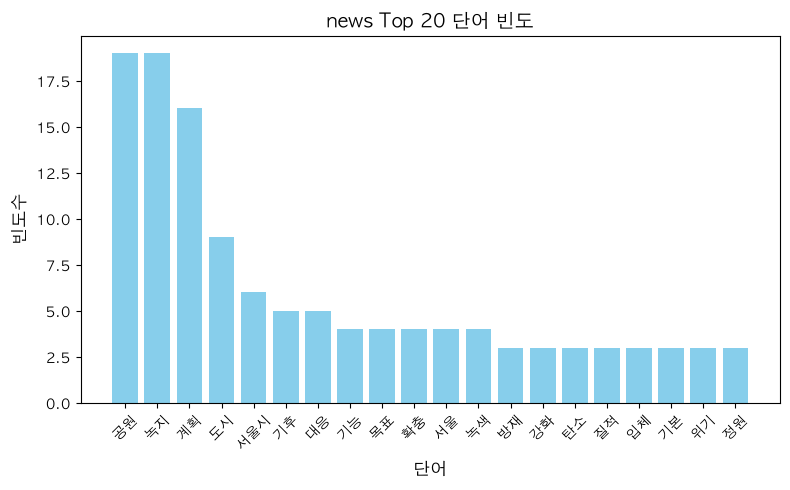

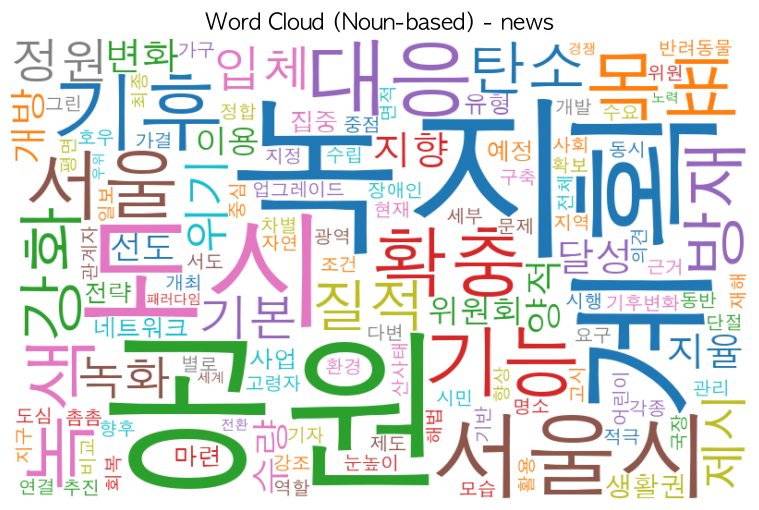

In [16]:
# 11~13 시각화 (막대그래프/히스토그램 + 워드 클라우드)


# ------------------------------------------
# 11) 시각화: 막대 그래프
# ------------------------------------------

# Counter 결과를 (단어, 빈도) 형태로 분리
labels, values = zip(*top20)

# 그래프 크기 설정
plt.figure(figsize=(8, 5))

# 막대그래프 그리기
plt.bar(labels, values, color="skyblue")

# 그래프 제목과 축 라벨
plt.title("news Top 20 단어 빈도", fontsize=14)
plt.xlabel("단어", fontsize=12)
plt.ylabel("빈도수", fontsize=12)

# x축 글자 겹침 방지
plt.xticks(rotation=45)

# 그래프 여백 조정
plt.tight_layout()

# 그래프 저장 (show() 뒤에는 그림이 비므로 먼저 저장)
plt.savefig(out_dir / "news_top20_bar.png", dpi=150)

# 그래프 출력
plt.show()

# 12) 워드클라우드를 위한 문자열 결합
text_for_wc = " ".join(filtered)

# 13) 워드클라우드 생성

wc = WordCloud(
    font_path=font_path,          # 한글 폰트 경로
    background_color="white",     # 배경색
    width=800,                    # 이미지 가로 크기(px)
    height=500,                   # 이미지 세로 크기(px)
    max_words=150,                # 최대 단어 수
    colormap="tab10",             # 색상 팔레트
    prefer_horizontal=0.9,        # 수평 배치 비율
    scale=1.0,                    # 렌더링 스케일(선명도)
    random_state=7,              # 재현성(결과 고정)
    collocations=False            # 두 단어 묶음(bigram) 끄기 → 단어 단위로만 집계
    # mask=mask                   # (선택) 마스킹 이미지 사용 시 주석 해제
).generate(text_for_wc)           # 또는 .generate_from_frequencies(freq_dict)


plt.figure(figsize=(10, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud (Noun-based) - news", fontsize=16)
plt.savefig(out_dir / "news_wordcloud.png", dpi=150, bbox_inches="tight")
plt.show()